## Import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)
from sqlalchemy import create_engine
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
print("Libraries imported.")

Libraries imported.


## Standardize names and inspect the raw dataset

In [3]:
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.astype(str).to_frame("data_type"))

print("\nNumeric summary:")
display(df.describe(include="number").T)

print("\nText/category summary:")
display(df.describe(include="object").T)

Columns:
['id', 'city', 'latitude', 'longitude', 'temperature', 'humidity', 'weather_description', 'wind_speed', 'fetched_at', 'weather_insight', 'feels_like', 'pressure', 'wind_direction', 'visibility', 'rain_1h', 'cloudiness', 'weather_main', 'weather_id', 'weather_icon', 'country', 'timezone']

Data types:


,data_type
id,int64
city,object
latitude,float64
longitude,float64
temperature,float64
humidity,int64
weather_description,object
wind_speed,float64
fetched_at,datetime64[ns]
weather_insight,object



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
id,95355.0,48199.890514,27526.952430,1.0000,24361.5000,48200.000,72038.5000,95877.0000
latitude,95355.0,27.745122,0.818648,26.4525,27.0667,27.678,28.1918,29.9667
longitude,95355.0,84.599124,2.127903,80.1700,83.0500,85.000,86.0833,88.1307
temperature,95355.0,24.330405,6.110957,-6.8600,20.8400,24.950,28.7800,44.0600
humidity,95355.0,74.118368,15.292881,11.0000,63.0000,75.000,87.0000,100.0000
wind_speed,95355.0,1.908921,1.186955,0.0000,1.1300,1.720,2.3700,14.6700
feels_like,67537.0,24.555014,7.637700,-10.7300,20.0600,24.430,30.1400,44.4500
pressure,67537.0,1013.310245,4.550391,998.0000,1010.0000,1013.000,1016.0000,1037.0000
wind_direction,67537.0,163.564757,99.715999,0.0000,72.0000,175.000,234.0000,360.0000
visibility,67231.0,9689.075888,1276.609991,3.0000,10000.0000,10000.000,10000.0000,10000.0000



Text/category summary:


,count,unique,top,freq
city,95355,244,Damauli,678
weather_description,95355,11,light rain,26076
weather_insight,95102,6,✅ Pleasant Weather,64898
weather_main,67537,4,Rain,24300
weather_icon,67537,12,10d,17105
country,67537,3,NP,63021


## Clean timestamps, duplicates, and numeric columns

In [4]:
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Exact duplicate rows removed:", duplicates_before)

df["fetched_at"] = pd.to_datetime(df["fetched_at"], errors="coerce")
invalid_time_count = int(df["fetched_at"].isna().sum())
df = df.dropna(subset=["fetched_at"]).copy()

df["city"] = df["city"].fillna("unknown_city").astype(str).str.strip()
df.loc[df["city"].eq(""), "city"] = "unknown_city"

numeric_candidates = [
    "latitude", "longitude", "temperature", "temp", "feels_like",
    "humidity", "pressure", "wind_speed", "wind_direction",
    "visibility", "rain_1h", "cloudiness", "clouds", "temp_min", "temp_max"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "temperature" not in df.columns:
    raise KeyError("The dataset needs a numeric 'temperature' column.")

df = df.sort_values(["city", "fetched_at"]).reset_index(drop=True)

print("Invalid timestamps removed:", invalid_time_count)
print("Rows after basic cleaning:", len(df))
print("Number of cities:", df["city"].nunique())
print("Time range:", df["fetched_at"].min(), "to", df["fetched_at"].max())
display(df.head())

Exact duplicate rows removed: 0
Invalid timestamps removed: 0
Rows after basic cleaning: 95355
Number of cities: 244
Time range: 2026-05-04 14:10:48 to 2026-10-27 19:16:42


,id,city,latitude,longitude,temperature,humidity,weather_description,wind_speed,fetched_at,weather_insight,feels_like,pressure,wind_direction,visibility,rain_1h,cloudiness,weather_main,weather_id,weather_icon,country,timezone
0,30716,Aanbu Khaireni,27.9042,84.5384,23.19,91,light rain,0.86,2026-09-02 20:43:27,💧 High Humidity,23.94,1006.0,243.0,10000.0,0.79,91.0,Rain,500.0,10n,NP,20700.0
1,30958,Aanbu Khaireni,27.9042,84.5384,26.78,80,light rain,1.51,2026-09-03 10:21:33,✅ Pleasant Weather,29.26,1007.0,245.0,10000.0,0.66,79.0,Rain,500.0,10d,NP,20700.0
2,31200,Aanbu Khaireni,27.9042,84.5384,23.68,94,moderate rain,1.04,2026-09-03 19:18:08,💧 High Humidity,24.56,1005.0,250.0,7349.0,1.99,96.0,Rain,501.0,10n,NP,20700.0
3,31442,Aanbu Khaireni,27.9042,84.5384,21.16,95,broken clouds,0.95,2026-09-04 05:41:03,💧 High Humidity,21.81,1006.0,20.0,10000.0,NaN,67.0,Clouds,803.0,04n,NP,20700.0
4,31684,Aanbu Khaireni,27.9042,84.5384,26.69,77,light rain,1.15,2026-09-04 15:42:40,✅ Pleasant Weather,28.84,1005.0,228.0,10000.0,0.73,49.0,Rain,500.0,10d,NP,20700.0


## Missing-value report and city coverage

,missing_count,missing_percent,dtype
rain_1h,71047,74.51,float64
visibility,28124,29.49,float64
pressure,27818,29.17,float64
wind_direction,27818,29.17,float64
weather_main,27818,29.17,object
country,27818,29.17,object
weather_icon,27818,29.17,object
timezone,27818,29.17,float64
weather_id,27818,29.17,float64
feels_like,27818,29.17,float64


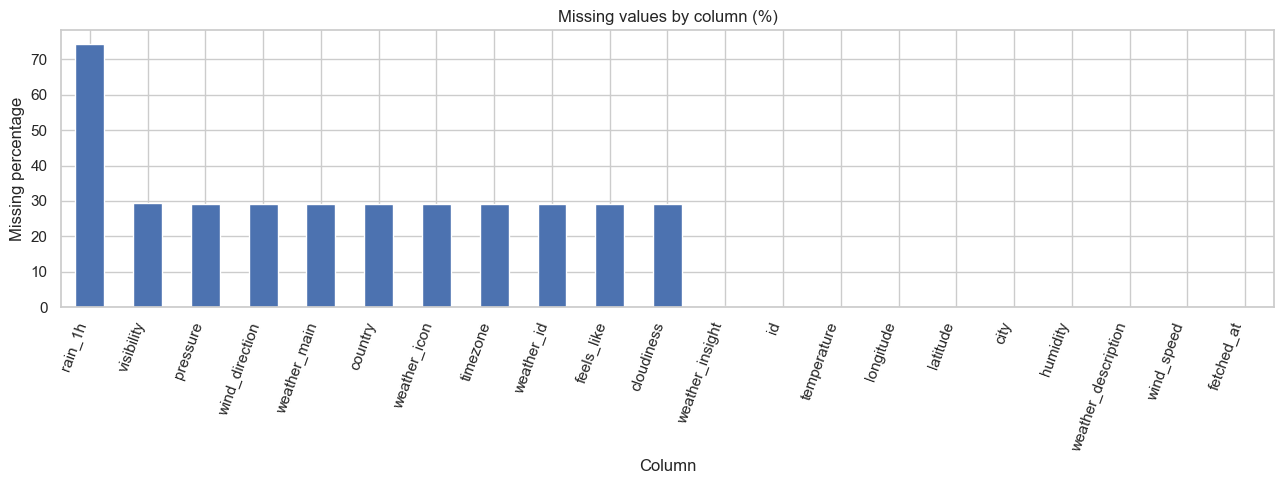

,record_count
city,
Damauli,678
Pokhara,491
Bhaktapur,490
Biratnagar,490
Dharan,490
Butwal,490
Lalitpur,490
Janakpur,489
Hetauda,489


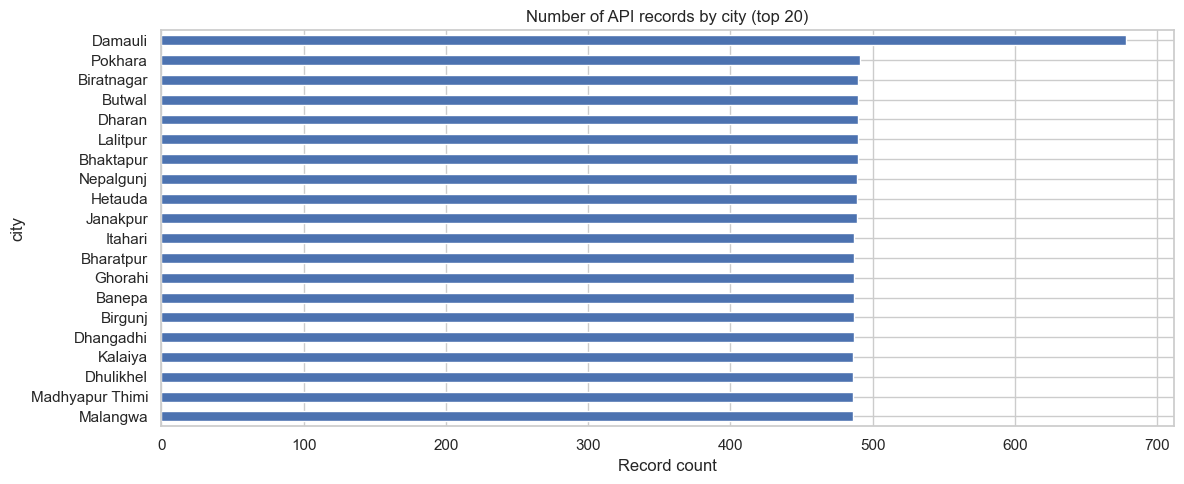

In [5]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing_report)

plt.figure(figsize=(13, 5))
missing_report["missing_percent"].sort_values(ascending=False).plot(kind="bar")
plt.title("Missing values by column (%)")
plt.ylabel("Missing percentage")
plt.xlabel("Column")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

city_counts = df["city"].value_counts()
display(city_counts.head(20).to_frame("record_count"))

plt.figure(figsize=(12, 5))
city_counts.head(20).sort_values().plot(kind="barh")
plt.title("Number of API records by city (top 20)")
plt.xlabel("Record count")
plt.tight_layout()
plt.show()

## EDA: feature distributions and outlier investigation

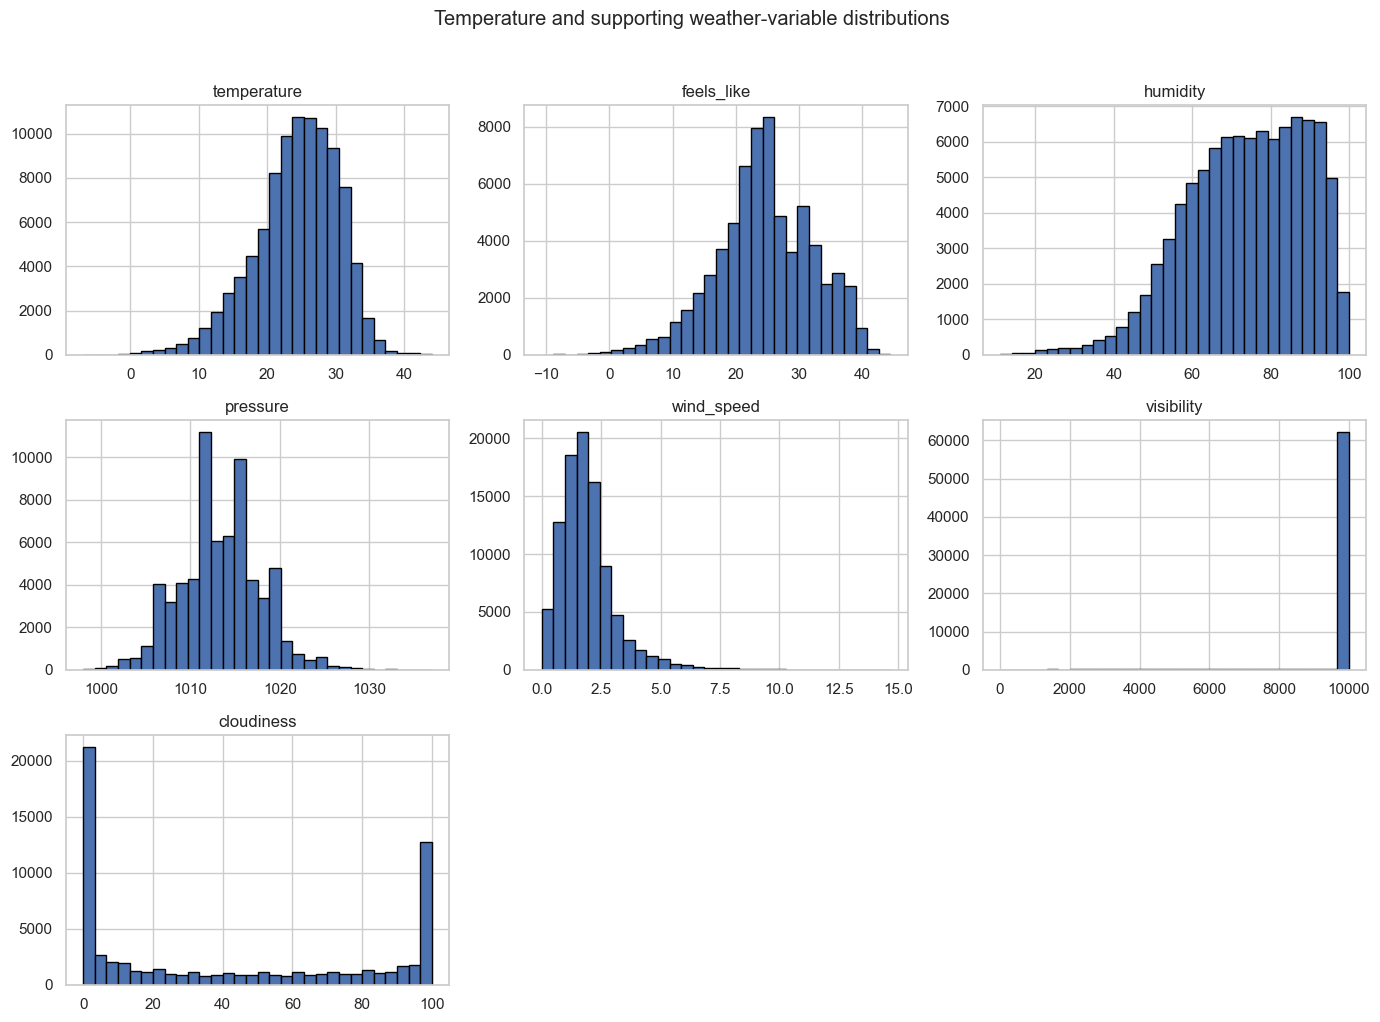

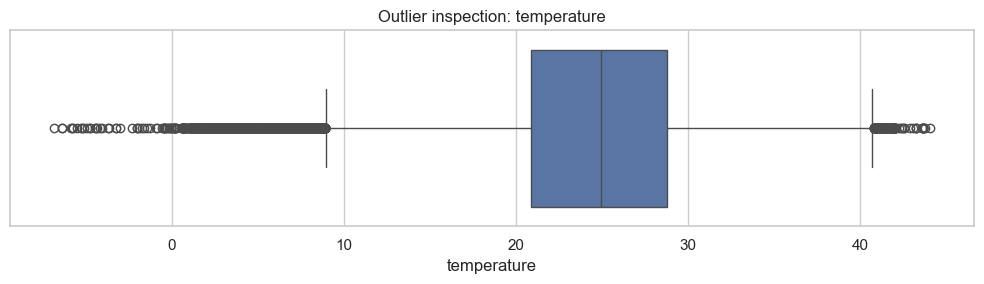

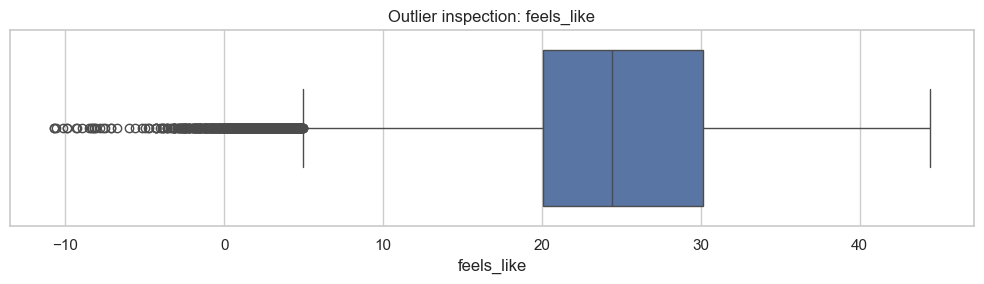

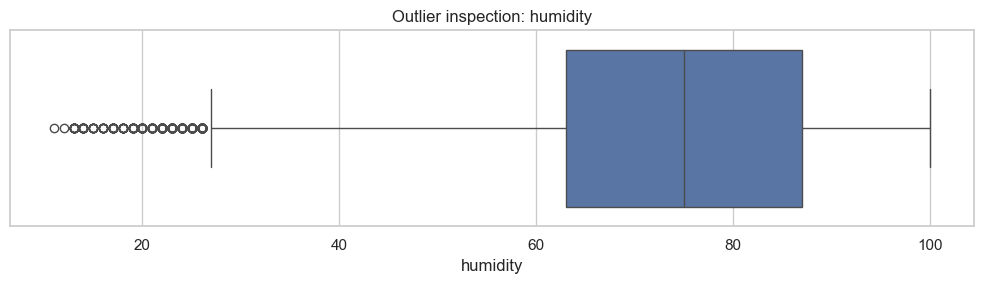

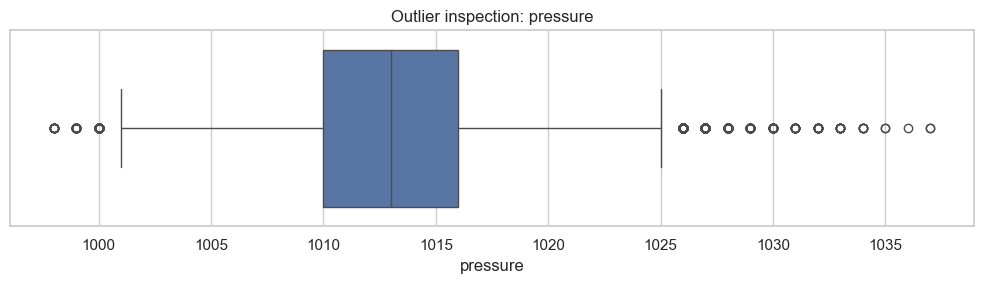

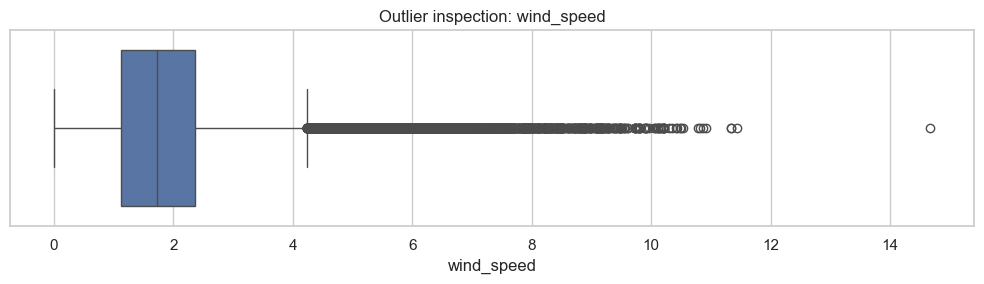

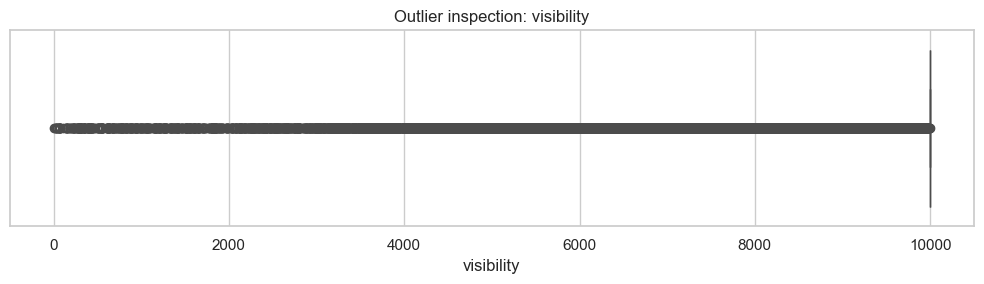

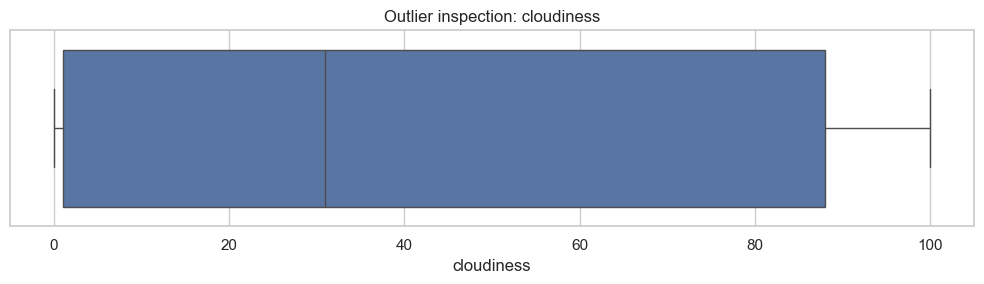

In [6]:
eda_numeric_cols = [
    col for col in [
        "temperature", "feels_like", "humidity", "pressure",
        "wind_speed", "visibility", "cloudiness"
    ]
    if col in df.columns and df[col].notna().any()
]

if eda_numeric_cols:
    df[eda_numeric_cols].hist(figsize=(14, 10), bins=30, edgecolor="black")
    plt.suptitle("Temperature and supporting weather-variable distributions", y=1.02)
    plt.tight_layout()
    plt.show()

    for col in eda_numeric_cols:
        plt.figure(figsize=(10, 3))
        sns.boxplot(x=df[col])
        plt.title(f"Outlier inspection: {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No numeric weather columns are available for EDA.")

## EDA: correlation heatmap

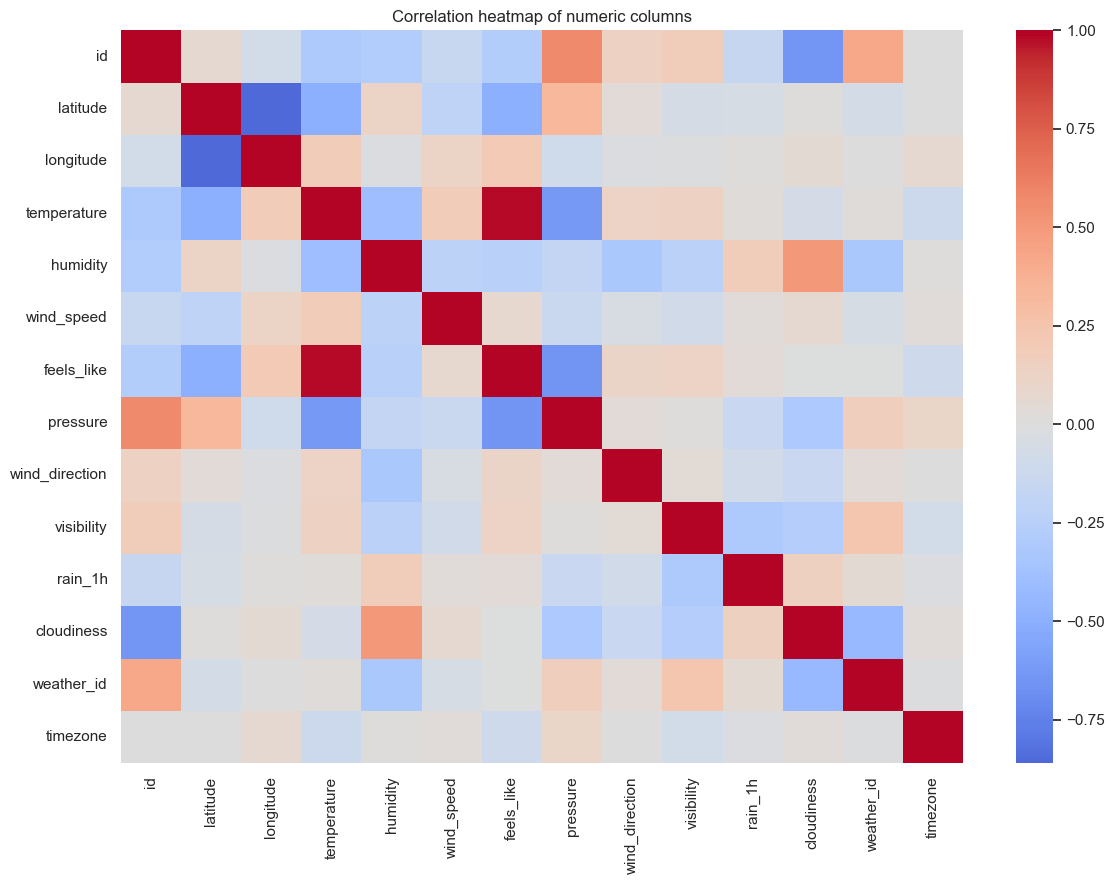

,id,latitude,longitude,temperature,humidity,wind_speed,feels_like,pressure,wind_direction,visibility,rain_1h,cloudiness,weather_id,timezone
id,1.00,0.06,-0.08,-0.30,-0.29,-0.15,-0.28,0.58,0.14,0.18,-0.16,-0.64,0.42,0.00
latitude,0.06,1.00,-0.86,-0.50,0.12,-0.20,-0.50,0.33,0.03,-0.05,-0.05,0.01,-0.07,0.00
longitude,-0.08,-0.86,1.00,0.19,-0.02,0.12,0.20,-0.09,-0.02,-0.01,0.02,0.05,0.00,0.06
temperature,-0.30,-0.50,0.19,1.00,-0.40,0.19,0.98,-0.62,0.13,0.15,0.03,-0.06,0.02,-0.12
humidity,-0.29,0.12,-0.02,-0.40,1.00,-0.23,-0.25,-0.17,-0.32,-0.23,0.17,0.50,-0.32,0.02
wind_speed,-0.15,-0.20,0.12,0.19,-0.23,1.00,0.08,-0.14,-0.04,-0.09,0.03,0.07,-0.05,0.03
feels_like,-0.28,-0.50,0.20,0.98,-0.25,0.08,1.00,-0.65,0.11,0.13,0.04,-0.01,-0.01,-0.11
pressure,0.58,0.33,-0.09,-0.62,-0.17,-0.14,-0.65,1.00,0.04,0.02,-0.14,-0.31,0.17,0.10
wind_direction,0.14,0.03,-0.02,0.13,-0.32,-0.04,0.11,0.04,1.00,0.05,-0.08,-0.14,0.04,-0.00
visibility,0.18,-0.05,-0.01,0.15,-0.23,-0.09,0.13,0.02,0.05,1.00,-0.30,-0.27,0.24,-0.08


In [7]:
numeric_data = df.select_dtypes(include=np.number)
if numeric_data.shape[1] >= 2:
    correlation = numeric_data.corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation heatmap of numeric columns")
    plt.tight_layout()
    plt.show()
    display(correlation.round(2))
else:
    print("At least two numeric columns are needed for a correlation heatmap.")

## EDA: temperature trends over time

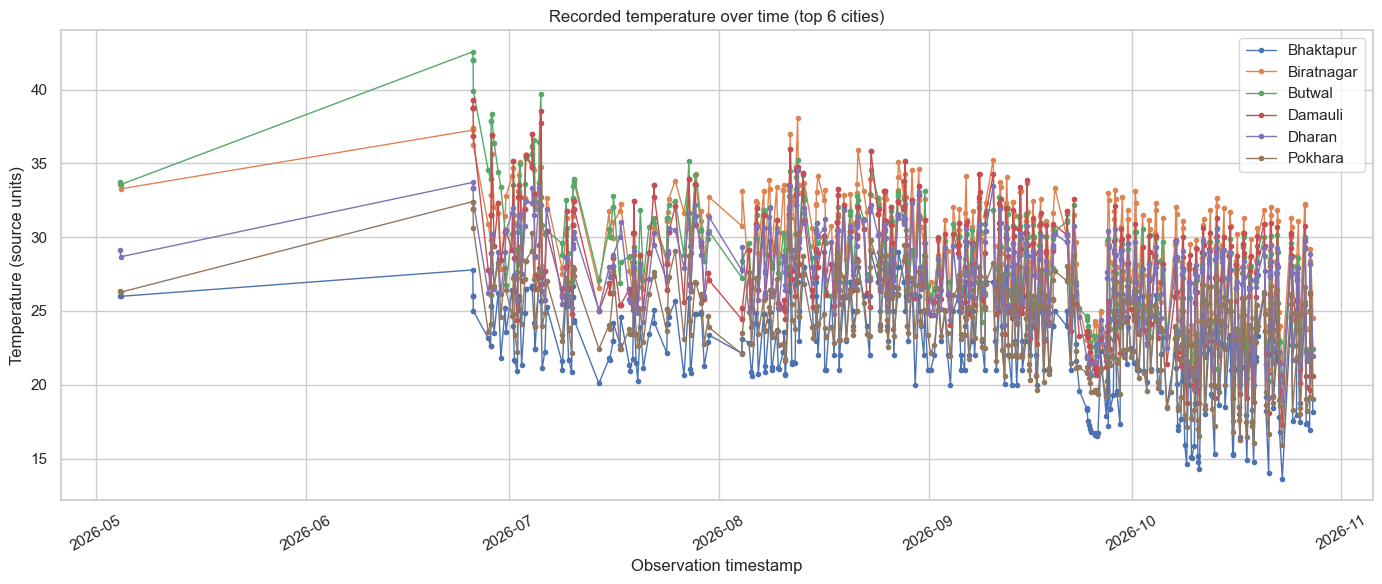

In [8]:
top_cities = df["city"].value_counts().head(6).index
trend_data = df[df["city"].isin(top_cities)].sort_values("fetched_at")

plt.figure(figsize=(14, 6))
for city_name, city_group in trend_data.groupby("city"):
    plt.plot(city_group["fetched_at"], city_group["temperature"], marker=".", linewidth=1, label=city_name)
plt.title("Recorded temperature over time (top 6 cities)")
plt.xlabel("Observation timestamp")
plt.ylabel("Temperature (source units)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Build a city-day dataset

In [9]:
df["date"] = df["fetched_at"].dt.floor("D")

aggregation_rules = {
    "temperature": ["max", "mean"],
}
for col in ["feels_like", "humidity", "pressure", "wind_speed", "visibility", "cloudiness"]:
    if col in df.columns:
        aggregation_rules[col] = ["mean"]

daily = df.groupby(["city", "date"]).agg(aggregation_rules)
daily.columns = [
    "_".join(str(part) for part in col if part)
    for col in daily.columns.to_flat_index()
]
daily = daily.reset_index()

daily_counts = df.groupby(["city", "date"]).size().rename("observations_per_day").reset_index()
daily = daily.merge(daily_counts, on=["city", "date"], how="left")
daily = daily.sort_values(["city", "date"]).reset_index(drop=True)

print("City-day rows:", len(daily))
print("Cities:", daily["city"].nunique())
display(daily.head(10))

City-day rows: 21761
Cities: 244


,city,date,temperature_max,temperature_mean,feels_like_mean,humidity_mean,pressure_mean,wind_speed_mean,visibility_mean,cloudiness_mean,observations_per_day
0,Aanbu Khaireni,2026-09-02,23.19,23.190000,23.940000,91.000000,1006.000000,0.860000,10000.0,91.000000,1
1,Aanbu Khaireni,2026-09-03,26.78,25.230000,26.910000,87.000000,1006.000000,1.275000,8674.5,87.500000,2
2,Aanbu Khaireni,2026-09-04,26.69,23.925000,25.325000,86.000000,1005.500000,1.050000,10000.0,58.000000,2
3,Aanbu Khaireni,2026-09-05,26.24,24.751667,25.246667,84.333333,1008.333333,1.058333,10000.0,85.500000,6
4,Aanbu Khaireni,2026-09-06,26.39,24.118000,24.700000,86.800000,1008.800000,0.932000,10000.0,94.000000,5
5,Aanbu Khaireni,2026-09-07,26.16,24.765000,25.317500,84.750000,1007.500000,1.312500,10000.0,86.000000,4
6,Aanbu Khaireni,2026-09-08,30.39,27.012000,29.212000,75.600000,1006.200000,0.838000,10000.0,51.800000,5
7,Aanbu Khaireni,2026-09-09,28.60,26.353333,28.760000,80.000000,1007.666667,0.936667,10000.0,70.000000,3
8,Aanbu Khaireni,2026-09-10,28.91,26.315000,28.165000,78.000000,1006.500000,0.600000,10000.0,82.000000,2
9,Aanbu Khaireni,2026-09-11,28.21,25.447143,27.035714,79.857143,1010.000000,1.024286,10000.0,64.857143,7


## Create leakage-aware features and tomorrow targets

In [10]:
# Add date features based on the date being forecast from.
daily["day_of_month"] = pd.to_datetime(daily["date"]).dt.day
daily["month"] = pd.to_datetime(daily["date"]).dt.month
daily["weekday"] = pd.to_datetime(daily["date"]).dt.weekday
daily["month_sin"] = np.sin(2 * np.pi * daily["month"] / 12)
daily["month_cos"] = np.cos(2 * np.pi * daily["month"] / 12)

# Current day's measurements are known inputs for the next-day prediction.
# Targets come from the next row only if its date is exactly tomorrow.
daily["next_date"] = daily.groupby("city")["date"].shift(-1)
daily["target_tomorrow_max_temperature"] = daily.groupby("city")["temperature_max"].shift(-1)

is_next_calendar_day = (
    pd.to_datetime(daily["next_date"]) - pd.to_datetime(daily["date"])
).dt.days.eq(1)
daily.loc[~is_next_calendar_day, "target_tomorrow_max_temperature"] = np.nan

daily = daily.sort_values(["date", "city"]).reset_index(drop=True)

print("Rows with tomorrow temperature target:",
      int(daily["target_tomorrow_max_temperature"].notna().sum()))
display(daily[["city", "date", "temperature_max", "next_date",
               "target_tomorrow_max_temperature"]].head(12))

Rows with tomorrow temperature target: 20540


,city,date,temperature_max,next_date,target_tomorrow_max_temperature
0,Bhaktapur,2026-05-04,25.99,2026-06-25,NaN
1,Biratnagar,2026-05-04,33.62,2026-06-25,NaN
2,Butwal,2026-05-04,33.74,2026-06-25,NaN
3,Dharan,2026-05-04,29.10,2026-06-25,NaN
4,Hetauda,2026-05-04,31.30,2026-06-25,NaN
5,Janakpur,2026-05-04,35.39,2026-06-25,NaN
6,Kathmandu,2026-05-04,26.15,2026-06-25,NaN
7,Lalitpur,2026-05-04,25.99,2026-06-25,NaN
8,Nepalgunj,2026-05-04,23.61,2026-06-25,NaN
9,Pokhara,2026-05-04,26.33,2026-06-25,NaN


## Select model features and create chronological train/test split

In [11]:
numeric_feature_candidates = [
    "temperature_max", "temperature_mean", "feels_like_mean", "humidity_mean",
    "pressure_mean", "wind_speed_mean", "visibility_mean", "cloudiness_mean",
    "observations_per_day", "day_of_month", "month", "weekday",
    "month_sin", "month_cos"
]
numeric_features = [
    col for col in numeric_feature_candidates
    if col in daily.columns and daily[col].notna().any()
]
categorical_features = ["city"]
feature_columns = numeric_features + categorical_features

regression_data = daily.dropna(subset=["target_tomorrow_max_temperature"]).copy()
regression_data = regression_data.sort_values("date").reset_index(drop=True)

if len(regression_data) < 30:
    raise ValueError(
        "Fewer than 30 city-days have a valid next-calendar-day temperature target. "
        "Collect more historical data before modelling."
    )

# Split by unique calendar date so records from the same day cannot appear
# in both training and testing partitions.
unique_dates = np.sort(regression_data["date"].dropna().unique())
date_split_position = int(len(unique_dates) * 0.80)
if date_split_position < 1 or date_split_position >= len(unique_dates):
    raise ValueError("Not enough distinct dates for an 80/20 chronological split.")

test_start_date = pd.Timestamp(unique_dates[date_split_position])
train_data = regression_data.loc[regression_data["date"] < test_start_date].copy()
test_data = regression_data.loc[regression_data["date"] >= test_start_date].copy()

if len(train_data) < 10 or len(test_data) < 2:
    raise ValueError("Not enough rows after splitting by calendar date.")

X_train = train_data[feature_columns]
X_test = test_data[feature_columns]
y_train_reg = train_data["target_tomorrow_max_temperature"]
y_test_reg = test_data["target_tomorrow_max_temperature"]

print("Features:", feature_columns)
print("Train rows:", len(train_data), "| Test rows:", len(test_data))
print("Train dates:", train_data["date"].min(), "to", train_data["date"].max())
print("Test dates:", test_data["date"].min(), "to", test_data["date"].max())

Features: ['temperature_max', 'temperature_mean', 'feels_like_mean', 'humidity_mean', 'pressure_mean', 'wind_speed_mean', 'visibility_mean', 'cloudiness_mean', 'observations_per_day', 'day_of_month', 'month', 'weekday', 'month_sin', 'month_cos', 'city']
Train rows: 15304 | Test rows: 5236
Train dates: 2026-06-27 00:00:00 to 2026-10-04 00:00:00
Test dates: 2026-10-05 00:00:00 to 2026-10-26 00:00:00


## Define preprocessing and regression models

In [12]:
def make_preprocessor(scale_numeric=False, num_cols=None, cat_cols=None):
    if num_cols is None:
        num_cols = numeric_features
    if cat_cols is None:
        cat_cols = categorical_features

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(steps=numeric_steps)

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = []
    if len(num_cols):
        transformers.append(("numeric", numeric_pipeline, num_cols))
    if len(cat_cols):
        transformers.append(("categorical", categorical_pipeline, cat_cols))

    return ColumnTransformer(transformers=transformers, remainder="drop")

regression_models = {
    "Baseline mean": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),
    "Random Forest Regressor": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestRegressor(
            n_estimators=200, max_depth=12, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

try:
    from xgboost import XGBRegressor
    regression_models["XGBoost Regressor"] = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", XGBRegressor(
            n_estimators=250, max_depth=5, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9,
            objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=4
        ))
    ])
    print("XGBoost Regressor enabled.")
except Exception:
    print("XGBoost not installed; optional model skipped. Install: python -m pip install xgboost")

print("Regression models:", list(regression_models.keys()))

XGBoost Regressor enabled.
Regression models: ['Baseline mean', 'Linear Regression', 'Random Forest Regressor', 'XGBoost Regressor']


## Train and evaluate regression models

In [13]:
regression_rows = []
trained_regressors = {}
regression_predictions_by_model = {}

for model_name, model in regression_models.items():
    try:
        model.fit(X_train, y_train_reg)
        predictions = model.predict(X_test)
        trained_regressors[model_name] = model
        regression_predictions_by_model[model_name] = predictions

        regression_rows.append({
            "model": model_name,
            "MAE": mean_absolute_error(y_test_reg, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions)),
            "R2": r2_score(y_test_reg, predictions) if len(y_test_reg) > 1 else np.nan
        })
        print("Trained:", model_name)
    except Exception as exc:
        print(f"Model skipped: {model_name}. Reason: {exc}")

regression_metrics = pd.DataFrame(regression_rows).sort_values("MAE")
display(regression_metrics.round(4))

Trained: Baseline mean
Trained: Linear Regression
Trained: Random Forest Regressor
Trained: XGBoost Regressor


,model,MAE,RMSE,R2
1,Linear Regression,2.0438,3.1421,0.7279
3,XGBoost Regressor,2.6241,3.4146,0.6787
2,Random Forest Regressor,2.6996,3.5721,0.6484
0,Baseline mean,4.8690,6.5212,-0.1719


## Dedicated tomorrow forecast: Naive, Random Forest, and XGBoost

,model,MAE,RMSE
0,Naive Forecast,2.339,3.840
1,XGBoost Regressor,2.624,3.415
2,Random Forest Regressor,2.700,3.572


Selected model for tomorrow's temperature: Naive Forecast
Why: it has the lowest MAE on the same chronological holdout dates.
Use RMSE as a secondary check; both metrics are in the source temperature units.


,city,date,today_max_temperature,actual_tomorrow_max_temperature,predicted_naive_forecast,predicted_random_forest_regressor,predicted_xgboost_regressor
15304,Manthali,2026-10-05,22.06,17.92,22.06,24.19,24.660000
15305,Mechinagar,2026-10-05,29.41,22.86,29.41,31.94,31.809999
15306,Matihani,2026-10-05,32.02,24.52,32.02,31.39,33.130001
15307,Martadi,2026-10-05,22.73,14.05,22.73,21.84,22.670000
15308,Manma Bazaar,2026-10-05,16.97,10.93,16.97,16.89,17.809999
15309,Waling,2026-10-05,23.90,18.47,23.90,25.47,25.520000
15310,Manang,2026-10-05,7.03,1.35,7.03,8.45,9.040000
15311,Manahari,2026-10-05,27.08,22.03,27.08,29.74,29.940001
15312,Malangwa,2026-10-05,31.26,24.85,31.26,33.40,32.720001
15313,Mahendranagar,2026-10-05,31.28,23.19,31.28,31.61,32.169998


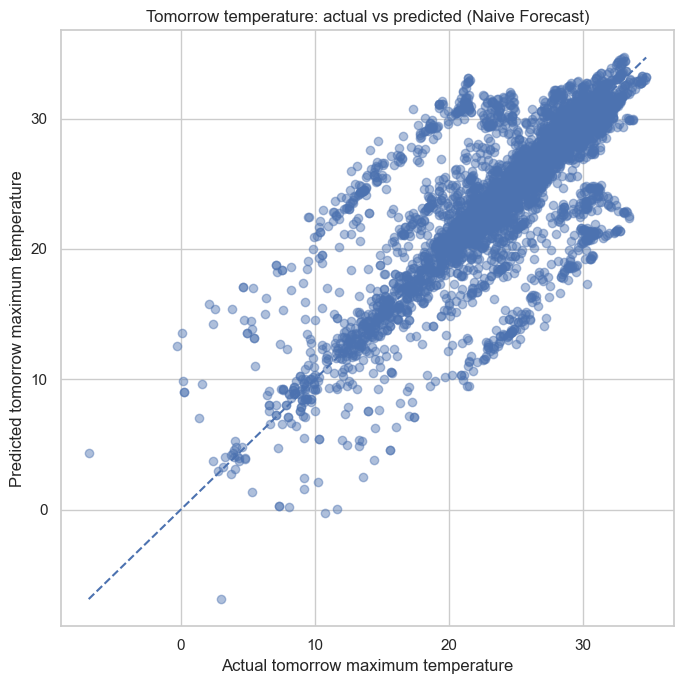

,city,last_observed_date,last_observed_max_temperature,forecast_date,naive_forecast_temperature,forecast_random_forest_regressor,forecast_xgboost_regressor
21523,Aanbu Khaireni,2026-10-27,22.92,2026-10-28,22.92,21.47,20.010000
21524,Achham,2026-10-27,21.63,2026-10-28,21.63,19.64,18.690001
21525,Amargadhi,2026-10-27,17.61,2026-10-28,17.61,15.99,14.990000
21526,Attariya,2026-10-27,25.72,2026-10-28,25.72,25.19,23.250000
21527,Bagchaur,2026-10-27,22.58,2026-10-28,22.58,20.20,19.959999
21528,Baglung,2026-10-27,24.46,2026-10-28,24.46,21.45,20.420000
14623,Bagmati,2026-09-28,31.64,2026-09-29,31.64,27.94,31.180000
21529,Bahrabise,2026-10-27,20.84,2026-10-28,20.84,19.97,19.980000
21530,Baitadi,2026-10-27,18.11,2026-10-28,18.11,16.45,15.430000
21531,Bajhang,2026-10-27,21.06,2026-10-28,21.06,17.85,18.570000


In [14]:
from sklearn.base import clone

# Compare all three approaches on the same chronological test rows.
# The naive forecast assumes tomorrow will be like today.
tomorrow_test = test_data.dropna(
    subset=["temperature_max", "target_tomorrow_max_temperature"]
).copy()

tomorrow_scores = []
tomorrow_test_predictions = {}

if not tomorrow_test.empty:
    X_tomorrow_test = tomorrow_test[feature_columns]
    y_tomorrow_test = tomorrow_test["target_tomorrow_max_temperature"]

    naive_predictions = tomorrow_test["temperature_max"].to_numpy()
    tomorrow_test_predictions["Naive Forecast"] = naive_predictions
    tomorrow_scores.append({
        "model": "Naive Forecast",
        "MAE": mean_absolute_error(y_tomorrow_test, naive_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_tomorrow_test, naive_predictions))
    })

    # Evaluate the tree models already trained on the training period.
    for model_name in ["Random Forest Regressor", "XGBoost Regressor"]:
        if model_name in trained_regressors:
            model_predictions = trained_regressors[model_name].predict(X_tomorrow_test)
            tomorrow_test_predictions[model_name] = model_predictions
            tomorrow_scores.append({
                "model": model_name,
                "MAE": mean_absolute_error(y_tomorrow_test, model_predictions),
                "RMSE": np.sqrt(mean_squared_error(y_tomorrow_test, model_predictions))
            })
        else:
            print(f"{model_name} is not available in this environment; skipped.")

    # 1) Compare model quality. Lower MAE is the primary selection rule.
    tomorrow_model_metrics = pd.DataFrame(tomorrow_scores).sort_values("MAE").reset_index(drop=True)
    display(tomorrow_model_metrics.round(3))

    if not tomorrow_model_metrics.empty:
        best_tomorrow_model = tomorrow_model_metrics.iloc[0]["model"]
        print(f"Selected model for tomorrow's temperature: {best_tomorrow_model}")
        print("Why: it has the lowest MAE on the same chronological holdout dates.")
        print("Use RMSE as a secondary check; both metrics are in the source temperature units.")

        # 2) Show actual and predicted values in one comparison table.
        tomorrow_comparison = tomorrow_test[
            ["city", "date", "temperature_max", "target_tomorrow_max_temperature"]
        ].copy()
        tomorrow_comparison = tomorrow_comparison.rename(columns={
            "temperature_max": "today_max_temperature",
            "target_tomorrow_max_temperature": "actual_tomorrow_max_temperature"
        })

        for model_name, values in tomorrow_test_predictions.items():
            safe_name = model_name.lower().replace(" ", "_")
            tomorrow_comparison[f"predicted_{safe_name}"] = values

        display(tomorrow_comparison.head(20).round(2))

        # 3) Plot actual versus predicted values for the selected best model.
        best_predictions = tomorrow_test_predictions[best_tomorrow_model]
        plt.figure(figsize=(7, 7))
        plt.scatter(y_tomorrow_test, best_predictions, alpha=0.45)
        lower = min(float(y_tomorrow_test.min()), float(np.min(best_predictions)))
        upper = max(float(y_tomorrow_test.max()), float(np.max(best_predictions)))
        plt.plot([lower, upper], [lower, upper], linestyle="--")
        plt.xlabel("Actual tomorrow maximum temperature")
        plt.ylabel("Predicted tomorrow maximum temperature")
        plt.title(f"Tomorrow temperature: actual vs predicted ({best_tomorrow_model})")
        plt.tight_layout()
        plt.show()

    # 4) Create next-day estimates for each city using its latest available row.
    latest_city_rows = (
        daily.sort_values(["city", "date"])
        .groupby("city", as_index=False, group_keys=False)
        .tail(1)
        .copy()
    )
    tomorrow_forecast_rows = latest_city_rows[["city", "date", "temperature_max"]].copy()
    tomorrow_forecast_rows["forecast_date"] = (
        pd.to_datetime(tomorrow_forecast_rows["date"]) + pd.Timedelta(days=1)
    )
    tomorrow_forecast_rows["naive_forecast_temperature"] = tomorrow_forecast_rows["temperature_max"]

    X_all_labelled = regression_data[feature_columns]
    y_all_labelled = regression_data["target_tomorrow_max_temperature"]
    X_latest = latest_city_rows[feature_columns]

    for model_name in ["Random Forest Regressor", "XGBoost Regressor"]:
        if model_name in regression_models:
            try:
                final_model = clone(regression_models[model_name])
                final_model.fit(X_all_labelled, y_all_labelled)
                safe_name = model_name.lower().replace(" ", "_")
                tomorrow_forecast_rows[f"forecast_{safe_name}"] = final_model.predict(X_latest)
            except Exception as exc:
                print(f"Could not create final {model_name} forecast: {str(exc)[:200]}")

    tomorrow_forecast_rows = tomorrow_forecast_rows.rename(columns={
        "date": "last_observed_date",
        "temperature_max": "last_observed_max_temperature"
    })
    display(tomorrow_forecast_rows.head(10).round(2))
    
else:
    print("Tomorrow model comparison skipped: no test rows have both today's and tomorrow's temperature.")

## Time-series setup: select one city and build daily maximum temperature series

Selected city: Biratnagar
Daily calendar points: 177
Fraction of missing daily values before interpolation: 0.35


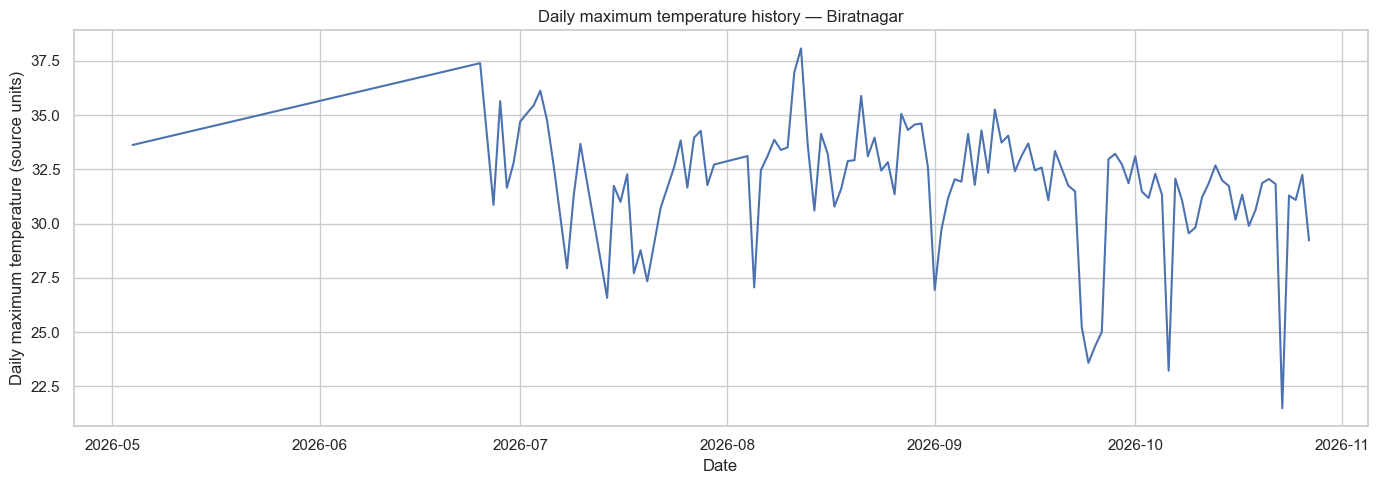

In [15]:
CITY_FOR_FORECAST = None  # Example: "Kathmandu"; None selects the city with most daily records
FORECAST_DAYS = 7

daily_temperature_counts = (
    daily.dropna(subset=["temperature_max"])
    .groupby("city")["temperature_max"].count()
    .sort_values(ascending=False)
)
if daily_temperature_counts.empty:
    raise ValueError("No daily maximum temperature values are available.")

if CITY_FOR_FORECAST is None:
    CITY_FOR_FORECAST = daily_temperature_counts.index[0]

city_daily = daily.loc[daily["city"].eq(CITY_FOR_FORECAST), ["date", "temperature_max"]].dropna()
city_daily = city_daily.drop_duplicates(subset=["date"], keep="last").sort_values("date")
city_daily = city_daily.set_index(pd.to_datetime(city_daily["date"]))["temperature_max"]
city_daily.index.name = "date"
city_daily = city_daily.sort_index()

# Reindex to a daily calendar. Only short internal gaps are interpolated.
full_daily_index = pd.date_range(city_daily.index.min(), city_daily.index.max(), freq="D")
city_daily = city_daily.reindex(full_daily_index)
city_daily.index.name = "date"
missing_day_fraction = float(city_daily.isna().mean())
print("Selected city:", CITY_FOR_FORECAST)
print("Daily calendar points:", len(city_daily))
print("Fraction of missing daily values before interpolation:", round(missing_day_fraction, 3))

city_daily_filled = city_daily.interpolate(limit=2, limit_area="inside").dropna()

plt.figure(figsize=(14, 5))
plt.plot(city_daily_filled.index, city_daily_filled.values)
plt.title(f"Daily maximum temperature history — {CITY_FOR_FORECAST}")
plt.xlabel("Date")
plt.ylabel("Daily maximum temperature (source units)")
plt.tight_layout()
plt.show()

if missing_day_fraction > 0.30:
    print("Warning: many daily values are missing. Forecasts may be unreliable.")
if len(city_daily_filled) < 60:
    print("Warning: fewer than 60 usable daily values. Prefer collecting more history before forecasting.")

## Seven-day model evaluation: naive benchmark and ARIMA

ARIMA holdout model could not be fitted: No supported index is available.


,model,MAE,RMSE
0,Naive last value,1.4184,2.7477


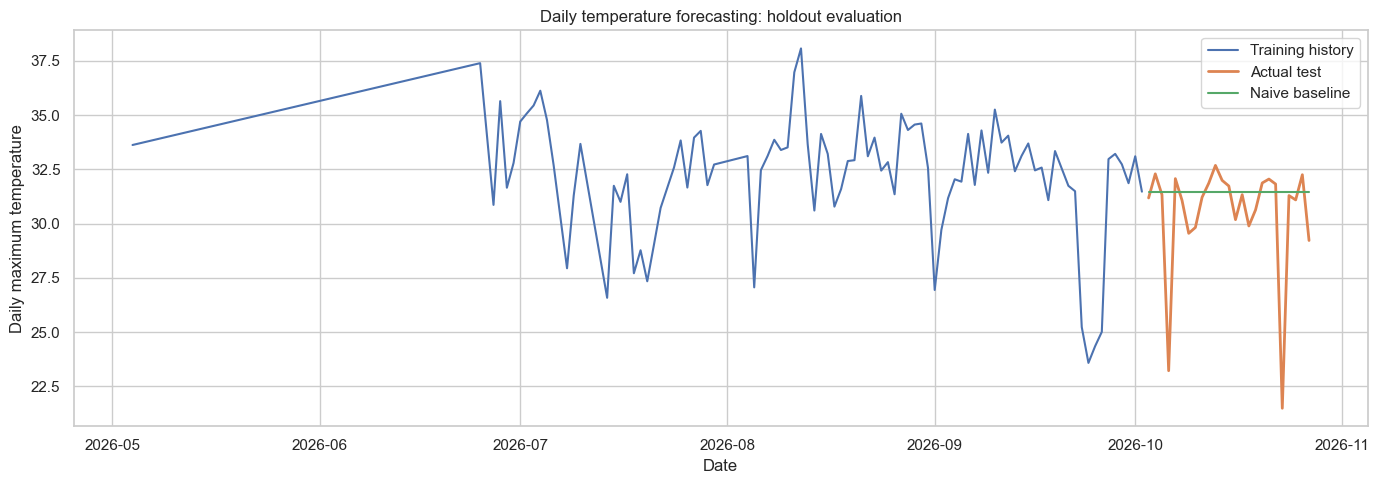

In [21]:
warnings.filterwarnings("ignore", category=Warning)
time_series_metrics = []
arima_test_predictions = None

if len(city_daily_filled) >= 60:
    ts_split = int(len(city_daily_filled) * 0.80)
    ts_train = city_daily_filled.iloc[:ts_split]
    ts_test = city_daily_filled.iloc[ts_split:]

    naive_predictions = np.repeat(float(ts_train.iloc[-1]), len(ts_test))
    time_series_metrics.append({
        "model": "Naive last value",
        "MAE": mean_absolute_error(ts_test, naive_predictions),
        "RMSE": np.sqrt(mean_squared_error(ts_test, naive_predictions))
    })

    try:
        from statsmodels.tsa.arima.model import ARIMA
        arima_test_model = ARIMA(ts_train, order=(2, 1, 2)).fit()
        arima_test_predictions = np.asarray(arima_test_model.forecast(steps=len(ts_test)))
        time_series_metrics.append({
            "model": "ARIMA(2,1,2)",
            "MAE": mean_absolute_error(ts_test, arima_test_predictions),
            "RMSE": np.sqrt(mean_squared_error(ts_test, arima_test_predictions))
        })
        print(arima_test_model.summary())
    except Exception as exc:
        print("ARIMA holdout model could not be fitted:", str(exc)[:300])

    ts_metrics_df = pd.DataFrame(time_series_metrics).sort_values("MAE")
    display(ts_metrics_df.round(4))

    plt.figure(figsize=(14, 5))
    plt.plot(ts_train.index, ts_train.values, label="Training history")
    plt.plot(ts_test.index, ts_test.values, label="Actual test", linewidth=2)
    plt.plot(ts_test.index, naive_predictions, label="Naive baseline")
    if arima_test_predictions is not None:
        plt.plot(ts_test.index, arima_test_predictions, label="ARIMA")
    plt.title("Daily temperature forecasting: holdout evaluation")
    plt.xlabel("Date")
    plt.ylabel("Daily maximum temperature")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("ARIMA holdout evaluation skipped: need at least 60 usable daily values.")

## ARIMA: forecast the next 7 days

In [17]:
warnings.filterwarnings("ignore", category=Warning)
future_arima = None

if len(city_daily_filled) >= 60:
    try:
        from statsmodels.tsa.arima.model import ARIMA
        final_arima_model = ARIMA(city_daily_filled, order=(2, 1, 2)).fit()
        arima_values = np.asarray(final_arima_model.forecast(steps=FORECAST_DAYS))
        future_dates = pd.date_range(
            city_daily_filled.index.max() + pd.Timedelta(days=1),
            periods=FORECAST_DAYS, freq="D"
        )
        future_arima = pd.DataFrame({
            "date": future_dates,
            "forecast_temperature": arima_values,
            "model": "ARIMA(2,1,2)"
        })
        display(future_arima)

        plt.figure(figsize=(12, 5))
        plt.plot(city_daily_filled.tail(min(60, len(city_daily_filled))), label="Recent history")
        plt.plot(future_arima["date"], future_arima["forecast_temperature"],
                 label="ARIMA forecast", marker="o")
        plt.title(f"Next {FORECAST_DAYS} daily temperature estimates — {CITY_FOR_FORECAST}")
        plt.xlabel("Date")
        plt.ylabel("Daily maximum temperature")
        plt.legend()
        plt.tight_layout()
        plt.show()
    except Exception as exc:
        print("ARIMA future forecast skipped:", str(exc)[:300])
else:
    print("ARIMA forecast skipped: need at least 60 usable daily values.")

ARIMA future forecast skipped: No supported index is available.


## LSTM: deep-learning 7-day forecast

In [18]:
lstm_future_output = None

try:
    import tensorflow as tf
    from sklearn.preprocessing import MinMaxScaler

    LOOKBACK_DAYS = 30
    MIN_LSTM_POINTS = 300

    if len(city_daily_filled) >= MIN_LSTM_POINTS:
        raw_values = city_daily_filled.to_numpy(dtype="float32").reshape(-1, 1)
        split_point = int(len(raw_values) * 0.80)

        scaler = MinMaxScaler()
        scaler.fit(raw_values[:split_point])
        scaled_values = scaler.transform(raw_values).ravel()

        X_windows, y_windows, target_indices = [], [], []
        for idx in range(LOOKBACK_DAYS, len(scaled_values)):
            X_windows.append(scaled_values[idx-LOOKBACK_DAYS:idx])
            y_windows.append(scaled_values[idx])
            target_indices.append(idx)

        X_windows = np.asarray(X_windows, dtype="float32").reshape(-1, LOOKBACK_DAYS, 1)
        y_windows = np.asarray(y_windows, dtype="float32")
        target_indices = np.asarray(target_indices)

        train_mask = target_indices < split_point
        test_mask = target_indices >= split_point

        X_lstm_train, y_lstm_train = X_windows[train_mask], y_windows[train_mask]
        X_lstm_test, y_lstm_test = X_windows[test_mask], y_windows[test_mask]

        tf.keras.utils.set_random_seed(RANDOM_STATE)
        lstm_model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(LOOKBACK_DAYS, 1)),
            tf.keras.layers.LSTM(32),
            tf.keras.layers.Dense(16, activation="relu"),
            tf.keras.layers.Dense(1)
        ])
        lstm_model.compile(optimizer="adam", loss="mse")
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        )
        lstm_model.fit(
            X_lstm_train, y_lstm_train,
            epochs=30, batch_size=32,
            validation_split=0.1,
            callbacks=[early_stopping],
            shuffle=False, verbose=0
        )

        lstm_test_scaled = lstm_model.predict(X_lstm_test, verbose=0)
        lstm_test_pred = scaler.inverse_transform(lstm_test_scaled).ravel()
        lstm_test_actual = scaler.inverse_transform(y_lstm_test.reshape(-1, 1)).ravel()

        lstm_holdout = pd.DataFrame([{
            "model": "LSTM",
            "MAE": mean_absolute_error(lstm_test_actual, lstm_test_pred),
            "RMSE": np.sqrt(mean_squared_error(lstm_test_actual, lstm_test_pred))
        }])
        display(lstm_holdout.round(4))
        plt.figure(figsize=(12, 5))
        plt.plot(lstm_test_actual, label="Actual test values")
        plt.plot(lstm_test_pred, label="LSTM predictions")
        plt.title("LSTM holdout: actual vs predicted daily maximum temperature")
        plt.xlabel("Test day index")
        plt.ylabel("Temperature")
        plt.legend()
        plt.tight_layout()
        plt.show()

        # Refit a fresh model on all available data for the final forecast.
        final_scaler = MinMaxScaler()
        final_scaled = final_scaler.fit_transform(
            city_daily_filled.to_numpy(dtype="float32").reshape(-1, 1)
        ).ravel()

        X_full, y_full = [], []
        for idx in range(LOOKBACK_DAYS, len(final_scaled)):
            X_full.append(final_scaled[idx-LOOKBACK_DAYS:idx])
            y_full.append(final_scaled[idx])
        X_full = np.asarray(X_full, dtype="float32").reshape(-1, LOOKBACK_DAYS, 1)
        y_full = np.asarray(y_full, dtype="float32")

        final_lstm = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(LOOKBACK_DAYS, 1)),
            tf.keras.layers.LSTM(32),
            tf.keras.layers.Dense(16, activation="relu"),
            tf.keras.layers.Dense(1)
        ])
        final_lstm.compile(optimizer="adam", loss="mse")
        final_lstm.fit(X_full, y_full, epochs=20, batch_size=32, shuffle=False, verbose=0)

        rolling_window = final_scaled[-LOOKBACK_DAYS:].copy()
        future_scaled_predictions = []
        for _ in range(FORECAST_DAYS):
            next_scaled = float(final_lstm.predict(
                rolling_window.reshape(1, LOOKBACK_DAYS, 1), verbose=0
            )[0, 0])
            future_scaled_predictions.append(next_scaled)
            rolling_window = np.append(rolling_window[1:], next_scaled)

        future_values = final_scaler.inverse_transform(
            np.asarray(future_scaled_predictions).reshape(-1, 1)
        ).ravel()
        future_dates = pd.date_range(
            city_daily_filled.index.max() + pd.Timedelta(days=1),
            periods=FORECAST_DAYS, freq="D"
        )
        lstm_future_output = pd.DataFrame({
            "date": future_dates,
            "forecast_temperature": future_values,
            "model": "LSTM"
        })
        display(lstm_future_output)
    else:
        print(f"LSTM skipped: this example recommends at least {MIN_LSTM_POINTS} daily values.")
except Exception as exc:
    print("LSTM skipped (TensorFlow unavailable or model issue).")
    print("Install with: python -m pip install tensorflow")
    print("Details:", str(exc)[:300])

LSTM skipped: this example recommends at least 300 daily values.


## Compare all available time-series holdout results

In [19]:
all_ts_results = []

if "time_series_metrics" in globals() and time_series_metrics:
    all_ts_results.extend(time_series_metrics)

if "lstm_holdout" in globals():
    all_ts_results.extend(lstm_holdout.to_dict("records"))

if all_ts_results:
    all_ts_metrics = pd.DataFrame(all_ts_results).drop_duplicates(subset=["model"], keep="last")
    all_ts_metrics = all_ts_metrics.sort_values("MAE")
    display(all_ts_metrics.round(4))
    # Pick a provisional winner only among models evaluated on comparable holdout periods.
    comparable = all_ts_metrics.dropna(subset=["MAE"]).sort_values("MAE")
    if not comparable.empty:
        best_7day_model = comparable.iloc[0]["model"]
        print(f"Best available 7-day model by holdout MAE: {best_7day_model}")
        print("Treat this as a provisional winner: compare holdout windows and data coverage before making a final claim.")
else:
    print("No time-series model metrics are available. Check history length and optional dependencies.")

,model,MAE,RMSE
0,Naive last value,1.4184,2.7477


Best available 7-day model by holdout MAE: Naive last value
Treat this as a provisional winner: compare holdout windows and data coverage before making a final claim.


## Display a project summary

In [23]:
project_summary = pd.DataFrame({
    "item": ["Cleaned API records", "Cities", "Timestamp column", "First observation", "Last observation", "City-day rows"],
    "value": [f"{len(df):,}", f"{df['city'].nunique():,}", "fetched_at", str(df["fetched_at"].min()), str(df["fetched_at"].max()), f"{len(daily):,}"]
})
display(project_summary)

print("\nRegression model comparison:")
if "regression_metrics" in globals() and not regression_metrics.empty:
    display(regression_metrics)
else:
    print("No regression models completed.")

print("\nTomorrow forecast comparison:")
if "tomorrow_model_metrics" in globals() and not tomorrow_model_metrics.empty:
    display(tomorrow_model_metrics)
else:
    print("No tomorrow forecast metrics available.")

print("\nTime-series forecasting comparison:")
if "all_ts_metrics" in globals() and not all_ts_metrics.empty:
    display(all_ts_metrics)
else:
    print("No time-series metrics available.")

,item,value
0,Cleaned API records,"95,355"
1,Cities,244
2,Timestamp column,fetched_at
3,First observation,2026-05-04 14:10:48
4,Last observation,2026-10-27 19:16:42
5,City-day rows,"21,761"



Regression model comparison:


,model,MAE,RMSE,R2
1,Linear Regression,2.043805,3.142102,0.727920
3,XGBoost Regressor,2.624058,3.414566,0.678687
2,Random Forest Regressor,2.699622,3.572081,0.648359
0,Baseline mean,4.868995,6.521171,-0.171946



Tomorrow forecast comparison:


,model,MAE,RMSE
0,Naive Forecast,2.339204,3.839687
1,XGBoost Regressor,2.624058,3.414566
2,Random Forest Regressor,2.699622,3.572081



Time-series forecasting comparison:


,model,MAE,RMSE
0,Naive last value,1.4184,2.747668
